# 2. An LSO-informed STM grey box

The six states are position and velocity departure from the nominal NRHO. In corridor-scaled coordinates,

$$e_{k+1}=A_k e_k+B_k\operatorname{diag}(g)u_k+w_k,\qquad z_{j,k}=h_j(t_k,x_{\rm nom}(t_k))+C_{j,k}e_k+v_{j,k},$$
$$\dot\Phi=F(t)\Phi,\quad A_k=J^{-1}\Phi(t_{k+1},t_k)J,\quad C_{j,k}=\left.\frac{\partial h_j}{\partial x}\right|_{x_{\rm nom}(t_k)}J.$$

$z_{j,k}$ contains the two angles from visible LSO $j$, so **$C_{j,k}$ is not the identity**. The measurement noise enters additively after the ideal angle map: $v_{j,k}\sim\mathcal{N}(0,R)$ with $R=\sigma_\theta^2 I_2$ and $\sigma_\theta=1$ arcsec in the synthetic sensor generator. Draws are independent across angle components, sites and epochs, which is a white-noise assumption. No real sensor calibration data are used to justify white or Gaussian noise, and bias or colored noise are not modeled. The innovation tests check this assumption against the synthetic data. Known physics fixes the STM. Training estimates three actuator gains $g$. This is a locally linear, phase-dependent model of the nonlinear orbit/angle system.

In [1]:
from pathlib import Path
import json
import numpy as np
from IPython.display import display, Markdown
from halo_tracking import stationkeeping as physics
from halo_tracking import lso_stationkeeping as sk
from halo_tracking import stationkeeping_diagnostics as sd
from halo_tracking import lso_diagnostics as ld
from halo_tracking import lso_report_plots as plots
ROOT=Path.cwd()
if not (ROOT/'configs').exists(): ROOT=ROOT.parent
OUT=ROOT/'artifacts'/'stationkeeping'
OUT.mkdir(parents=True,exist_ok=True)
plots.style()
def table(headers,rows):
    display(Markdown('| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+
                     '\n'.join('| '+' | '.join(map(str,row))+' |' for row in rows)))

orbit,data=sk.restore_study(ROOT,OUT/'data')
fit=sk.fit_greybox(orbit,data['training']);gains=fit['gains']
table(['Axis','Estimated gain','Conditional standard error'],[('xyz'[j],f'{gains[j]:.4g}',f"{fit['gain_standard_errors'][j]:.3g}") for j in range(3)])
print('Angular-innovation sensitivity singular values:',fit['jacobian_singular_values'])
(OUT/'greybox_fit.json').write_text(json.dumps({k:v.tolist() if isinstance(v,np.ndarray) else v for k,v in fit.items()},indent=2)+'\n')

Angular-innovation sensitivity singular values: [219.88160348 156.39722837  69.6766566 ]
Out[1]: 533


| Axis | Estimated gain | Conditional standard error |
| --- | --- | --- |
| x | 0.9931 | 0.00456 |
| y | 1.046 | 0.00665 |
| z | 0.9644 | 0.0142 |

## Identification and held-out validation

Following Studios 5 and 11, minimize covariance-standardized **raw angular innovations** on training trajectories, updating only when an LSO is visible. No generated full-state observations or saved truth enter the fit. Filtered state histories are correlated outputs, so they support exploratory plots and guidance, not independent-measurement regression.

Validation compares unity and fitted gains. Independent test trajectories assess angular prediction and navigation accuracy. Free propagation uses its initial angular update and then the known commands, with no later measurements. Truth is used only to evaluate state errors.

| Dataset / model | Angular RMSE [arcsec] | Navigation position RMSE [km] | Navigation velocity RMSE [m/s] |
| --- | --- | --- | --- |
| Validation: unity gains | 7.45 | 0.456 | 0.00694 |
| training | 5.17 | 0.388 | 0.00509 |
| validation | 7.41 | 0.456 | 0.00695 |
| test | 6.39 | 0.395 | 0.00521 |

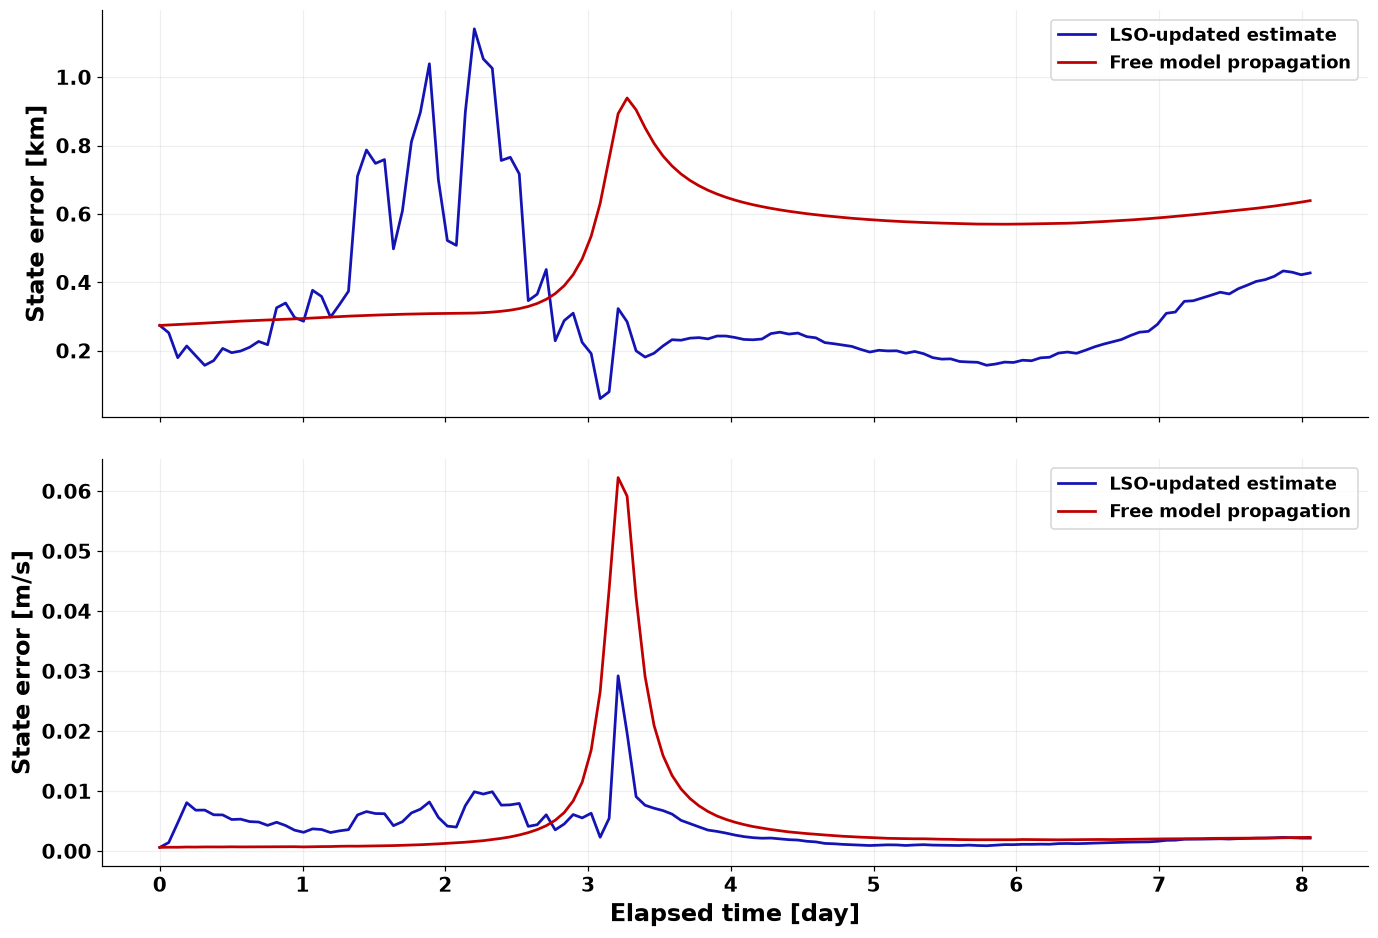

**Purpose:** Held-out truth is used only here to compare LSO-updated state estimates with free model propagation after its initial angular update.

**Result:** The LSO-updated 3-D RMSE is 0.395 km in position and 0.00521 m/s in velocity, quantifying navigation accuracy without treating estimated states as measurements.

In [2]:
scores={name:sk.prediction_scores(orbit,rec,gains) for name,rec in data.items()}
unity=sk.prediction_scores(orbit,data['validation'],np.ones(3))
table(['Dataset / model','Angular RMSE [arcsec]','Navigation position RMSE [km]','Navigation velocity RMSE [m/s]'],[(name,f"{q['angular_innovation_rmse_arcsec']:.3g}",f"{q['navigation']['position_rmse_km']:.3g}",f"{q['navigation']['velocity_rmse_m_s']:.3g}") for name,q in [('Validation: unity gains',unity)]+list(scores.items())])
(OUT/'prediction_scores.json').write_text(json.dumps(scores,indent=2)+'\n')
test=data['test'];pred=sk.predict(orbit,test,gains);free=sk.predict(orbit,test,gains,free_run=True)
plots.validation(orbit,test,pred,free,OUT/'figures')
np.savez_compressed(OUT/'test_predictions.npz',**pred,free_simulation=free['navigation'])

## Do the residuals support the predictor?

Use standardized angular innovations with actual time lags and visibility gaps intact. Ljung–Box uses eligible contiguous runs with Holm adjustment. A mask-conditioned Monte Carlo maximum-CCF test covers the input/channel/lag family. No gaps or independent trajectories are concatenated, and no fitted ARMA degrees of freedom are subtracted for the fixed model on test data.

ADF/KPSS also uses contiguous observed runs, reporting insufficient support explicitly. Residual whiteness checks whether the assumed noise model is adequate. Residual–input correlation checks whether the commanded impulses remain related to the prediction error. Passing these checks does not guarantee that the orbit model or the station-keeping controller is accurate.

Out[3]: 75


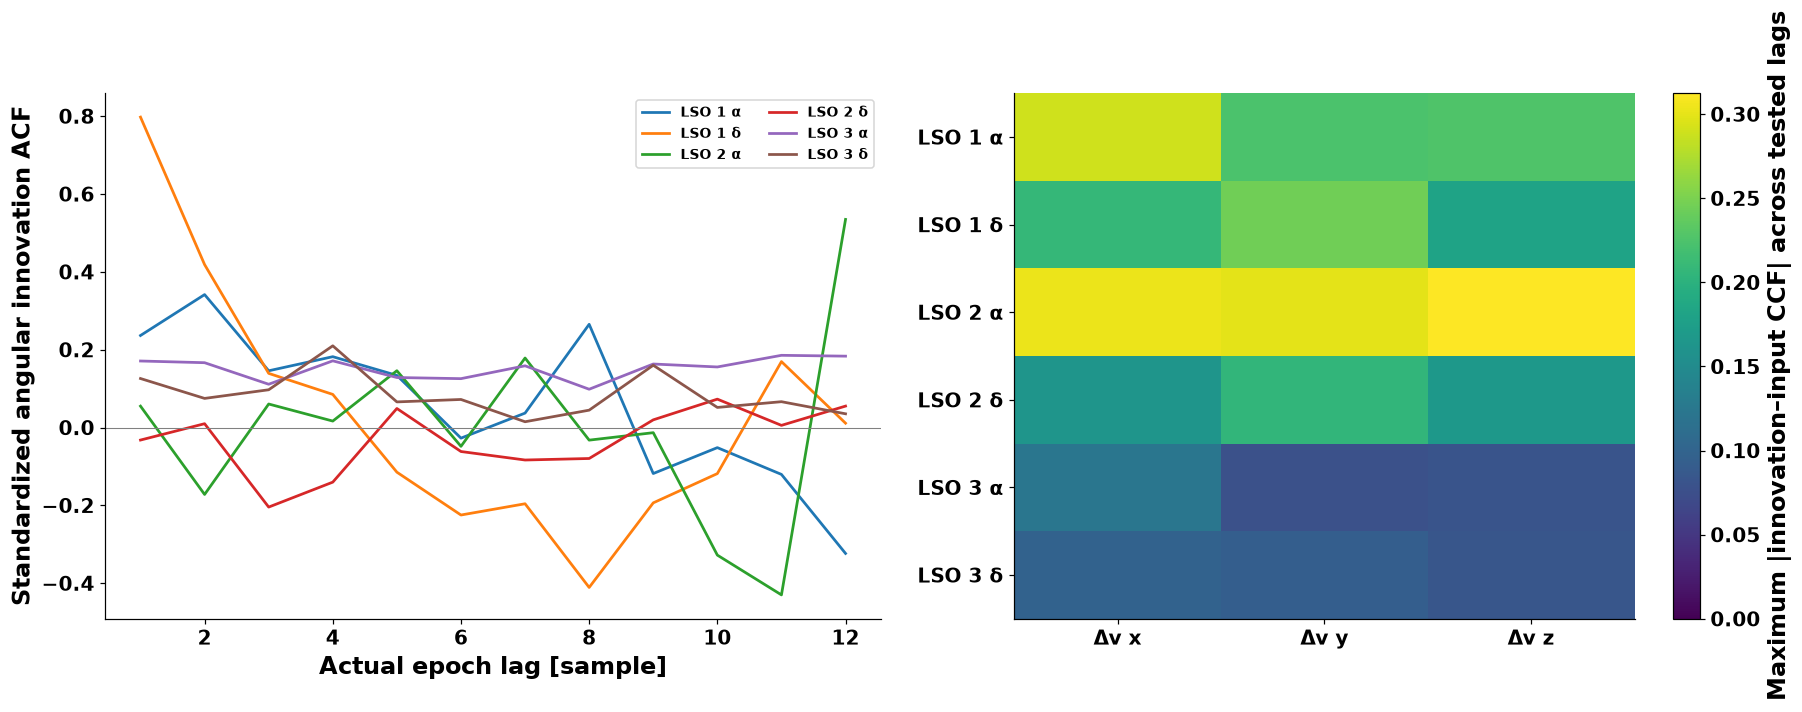

**Purpose:** The ACF and residual–input correlation screen the raw angular predictor while preserving visibility gaps and true time lags.

**Result:** Holm-adjusted Ljung–Box tests reject 2 of 8 eligible contiguous runs and the mask-conditioned global CCF p-value is 0.895, which assesses predictor/noise adequacy rather than controller success.

| Angular channel | Contiguous samples | ADF p | KPSS p | Joint reading |
| --- | --- | --- | --- | --- |
| LSO 1 alpha | 14 | insufficient data | insufficient data | insufficient contiguous observations |
| LSO 1 delta | 14 | insufficient data | insufficient data | insufficient contiguous observations |
| LSO 2 alpha | 15 | insufficient data | insufficient data | insufficient contiguous observations |
| LSO 2 delta | 15 | insufficient data | insufficient data | insufficient contiguous observations |
| LSO 3 alpha | 71 | 0.985 | 0.01 | evidence against level stationarity |
| LSO 3 delta | 71 | 0.182 | 0.01 | evidence against level stationarity |

In [3]:
residual=ld.residual_report(pred['standardized'],test.u,orbit.settings['residual_lags'])
plots.residuals(residual,OUT/'figures')
stationarity_rows=ld.stationarity_rows(pred['standardized'])
def fmt(p): return 'insufficient data' if p is None else f'{p:.3g}'
table(['Angular channel','Contiguous samples','ADF p','KPSS p','Joint reading'],[(r['channel'],r['contiguous_samples'],fmt(r['adf_p']),fmt(r['kpss_p']),r['reading']) for r in stationarity_rows])
(OUT/'innovation_stationarity.json').write_text(json.dumps(stationarity_rows,indent=2)+'\n')
np.savez_compressed(OUT/'residual_checks.npz',**{k:v for k,v in residual.items() if isinstance(v,np.ndarray)})
(OUT/'optical_residual_summary.json').write_text(json.dumps({k:v for k,v in residual.items() if not isinstance(v,np.ndarray)},indent=2)+'\n')

## Do LSO-guided station keeping limits hold over a year?

Guidance uses only the LSO-derived departure estimate, with state updates at every measurement sample and planner calls at every measurement sample (about 1.5 hours). Candidate burns are checked by nonlinear propagation. The one-year run reports sampled corridor performance and the cumulative commanded Δv from the actual simulated impulses.

This is one simulated year, not a continuous-time guarantee or a population success rate. A failure can arise from navigation, prediction or the single-impulse planner.

findfont: Failed to find font weight bold for STIXSizeFiveSym, now using 400.
findfont: Failed to find font weight bold for cmmi10, now using 400.
findfont: Failed to find font weight bold for cmsy10, now using 400.
findfont: Failed to find font weight bold for cmr10, now using 400.
findfont: Failed to find font weight bold for cmtt10, now using 400.
findfont: Failed to find font weight bold for cmti10, now using 400.
findfont: Failed to find font weight bold for cmb10, now using 400.
findfont: Failed to find font weight bold for cmss10, now using 400.
findfont: Failed to find font weight bold for cmex10, now using 400.
findfont: Failed to find font weight bold for DejaVu Sans Display, now using 400.


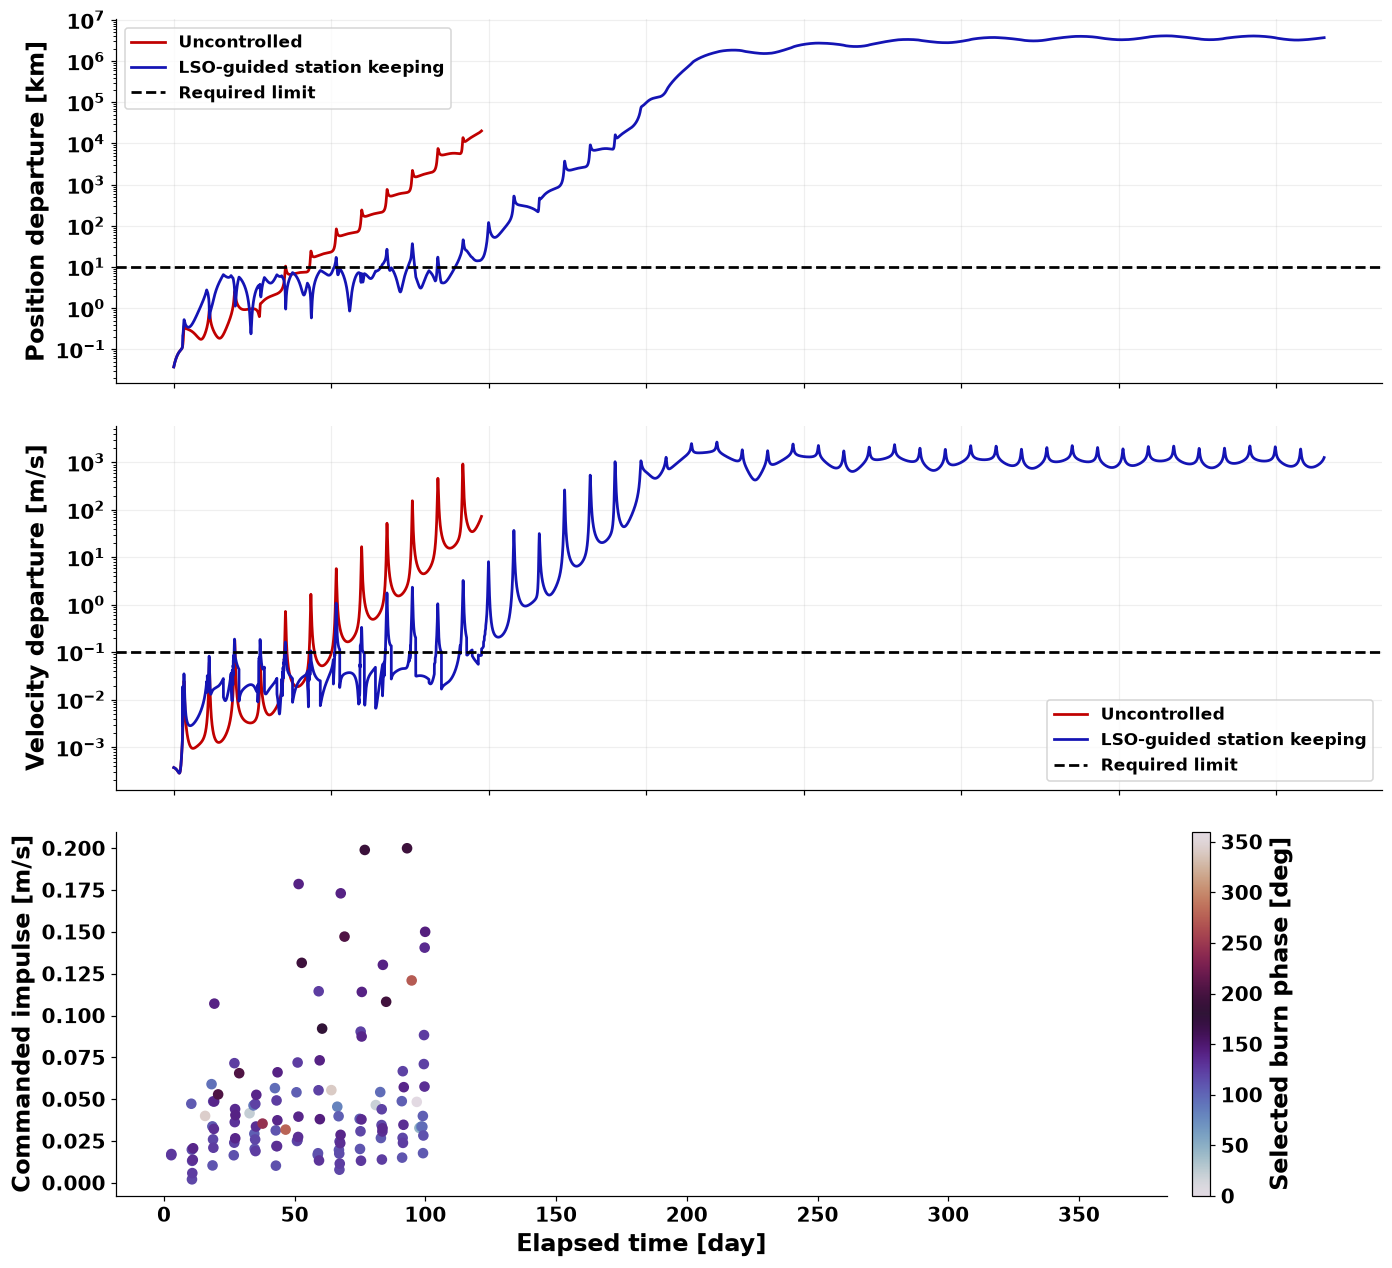

**Purpose:** True departure norms evaluate the LSO-guided controller, and coloured impulse markers show the magnitudes and orbital phases it selected.

**Result:** Peak position and velocity departures are 4.11e+06 km and 2.67e+03 m/s, so this run does not establish satisfaction of both corridor limits over the requested span.

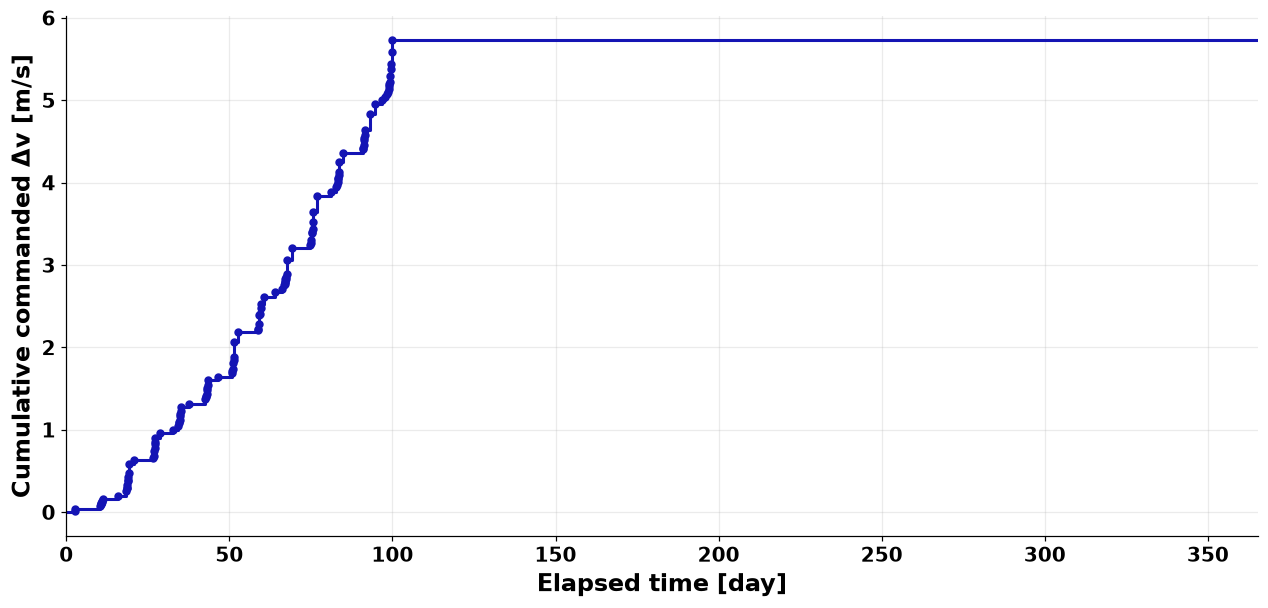

**Purpose:** The curve sums the magnitudes of commanded impulses over the simulated trajectory, so it reports accumulated Δv rather than a linearized yearly extrapolation.

**Result:** The completed requested horizon covers 365.25 days and accumulates 5.733 m/s of commanded Δv across 116 burns. The path leaves the required corridor at day 19.15, so this simulated total is not a feasible annual station-keeping budget.

| Metric | Observed value |
| --- | --- |
| completed | True |
| requested_duration_days | 365.25 |
| last_day | 365.25 |
| planning_stride_steps | 1 |
| maximum_position_km | 4108987.973214662 |
| maximum_velocity_m_s | 2674.0276908510514 |
| all_evaluated_samples_inside | False |
| first_sampled_exit_day | 19.145790906152698 |
| burns | 116 |
| total_commanded_delta_v_m_s | 5.732861087605663 |
| annual_delta_v_m_s | 5.732861087605663 |
| visible_epoch_fraction | 0.42692175112030334 |

**Noise-model conclusion:** 2/8 eligible whiteness tests reject after adjustment and the global residual–input p-value is 0.895, so these tests flag predictor/noise inadequacy.

**Station-keeping conclusion:** the LSO-guided baseline does not establish the full corridor requirement, with observed peaks of 4.11e+06 km and 2.67e+03 m/s.

In [4]:
trial=sk.stationkeeping_trial(
    orbit,gains,
    duration_days=orbit.settings['annual_horizon_days'],
    planning_stride_steps=orbit.settings['annual_planning_stride_steps'],
    stop_on_departure_cutoff=False)
if (OUT/'uncontrolled.npz').exists():
    with np.load(OUT/'uncontrolled.npz') as z: no_day,no_y=z['day'],z['output']
else: no_day,no_y,_=sk.uncontrolled(orbit)
plots.controlled(orbit,trial,no_day,no_y,OUT/'figures')
plots.annual_delta_v(trial,OUT/'figures')
summary=trial['summary']
table(['Metric','Observed value'],[(k,summary[k]) for k in ('completed','requested_duration_days','last_day','planning_stride_steps','maximum_position_km','maximum_velocity_m_s','all_evaluated_samples_inside','first_sampled_exit_day','burns','total_commanded_delta_v_m_s','annual_delta_v_m_s','visible_epoch_fraction')])
np.savez_compressed(OUT/'closed_loop.npz',**{k:v for k,v in trial.items() if k!='summary'})
(OUT/'closed_loop_summary.json').write_text(json.dumps(summary,indent=2)+'\n')
rejects=int(np.nansum(residual['ljung_box_holm_p']<.05))
display(Markdown(f'**Noise-model conclusion:** {rejects}/{residual["eligible_whiteness_tests"]} eligible whiteness tests reject after adjustment and the global residual–input p-value is {residual["ccf_global_p"]:.3g}, so these tests '+('flag predictor/noise inadequacy.' if rejects or residual['ccf_global_p']<.05 else 'do not reject the tested assumptions at 5%, without proving the model correct.')))
display(Markdown('**Station-keeping conclusion:** '+('both required norms remain inside their limits at all evaluated samples of the completed run.' if summary['completed'] and summary['all_evaluated_samples_inside'] else f'the LSO-guided baseline does not establish the full corridor requirement, with observed peaks of {summary["maximum_position_km"]:.3g} km and {summary["maximum_velocity_m_s"]:.3g} m/s.')))

## Next model discussion

The physical basis and measured phase dependence support a periodic STM starting model, not a globally LTI one. Review LSO availability, gain uncertainty, raw angular residuals and navigation error before selecting a local OE/BJ model or periodic parameter basis (Studio 13). NARX remains deferred. Improving navigation or the burn planner may matter more than increasing black-box complexity.